# Step 7 — Data Preparation & Exploratory Analysis Report
**Seasonal Flight Delays at New York City Airports (2013)**  
**BAN 5103 — Introduction to Statistics for Business Analytics**  
**Team:** Hyejung Jung · Caleb Ogier · Kira J. Sandys · Diana Navarrete

**Scope:** This notebook consolidates Steps 1–6 into a reproducible descriptive report. It is **not** a completed inferential/statistical analysis or the final course project submission. Results from ANOVA, regression, hypothesis tests, and model diagnostics will be added in the later statistical-analysis milestone, after they are actually performed.

**Research question:** How are season, airline, scheduled departure time, flight distance, and weather conditions associated with flight arrival delays at major New York City airports?

## 1. Business context and data
Flight delays can affect airline scheduling, operational planning, and customer experience. Our stakeholders are airline operations managers considering scheduling and resource-allocation decisions.

We use the publicly available [`nycflights13`](https://nycflights13.tidyverse.org/) flights, hourly weather, and airline reference tables for flights departing EWR, JFK, and LGA in 2013. The unit of analysis is **one flight with an observed arrival delay**. The response variable `arr_delay` is in minutes (positive = late; negative = early).

**Important:** Observed associations are not evidence of causation, and 2013 patterns should not be assumed to describe current operations.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
DATA = ROOT / "data" / "cleaned" / "analysis_ready_flights.csv"
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
assert DATA.is_file(), f"Cannot find {DATA}. Open this notebook from the project root."
df = pd.read_csv(DATA)
assert "arr_delay" in df.columns
assert df["arr_delay"].notna().all()
print(f"Analysis-ready dataset: {len(df):,} flights × {df.shape[1]} columns")
print(f"Available figures: {len(list(FIGURES.glob('*.png'))) if FIGURES.exists() else 0}")

Analysis-ready dataset: 327,346 flights × 34 columns
Available figures: 42


## 2. Data preparation and quality audit
We retained the original raw data and used the Step 3 cleaned dataset. Arrival delay was unavailable for some flights, so those rows cannot contribute to arrival-delay summaries. We joined airport-level hourly weather using `origin` and `time_hour` with a many-to-one merge, derived `season` from month and `scheduled_hour` from `sched_dep_time`, and did **not** delete extreme observed arrival delays.

Weather observations may be missing for some flights. A missing `arr_delay` does **not** by itself prove that a flight was canceled or diverted. The join key `time_hour` is the timestamp provided by the flight dataset, not a newly calculated scheduled departure timestamp. Detailed validation and audit tables are in `06_Data_Quality_Documentation.ipynb` and `results/tables/`.

In [2]:
raw_path = ROOT / "data" / "raw" / "flights.csv"
if raw_path.exists():
    raw = pd.read_csv(raw_path)
    overview = pd.DataFrame({
        "Metric": ["Original flight records", "Missing arrival delay", "Retained analysis flights", "Retained columns", "Missing outcome in cleaned data"],
        "Value": [len(raw), int(raw["arr_delay"].isna().sum()), len(df), df.shape[1], int(df["arr_delay"].isna().sum())]
    })
else:
    overview = pd.DataFrame({"Metric": ["Retained analysis flights", "Retained columns", "Missing outcome in cleaned data"], "Value": [len(df), df.shape[1], int(df["arr_delay"].isna().sum())]})
display(overview)
assert len(df) == 327346, "Dataset size differs from the validated Step 6 dataset. Investigate before proceeding."
assert df.shape[1] == 34, "Column count differs from the validated Step 6 dataset."
if raw_path.exists():
    assert len(raw) == 336776
    assert raw["arr_delay"].isna().sum() == 9430
    assert len(raw) - raw["arr_delay"].isna().sum() == len(df)

,Metric,Value
0,Original flight records,336776
1,Missing arrival delay,9430
2,Retained analysis flights,327346
3,Retained columns,34
4,Missing outcome in cleaned data,0


## 3. Overall arrival-delay distribution
We report both mean and median because long right-tail delays can pull the mean upward. Delay thresholds are descriptive; a flight arriving exactly 15 minutes late is **not** included in the `>15` category.

In [3]:
delay = df["arr_delay"]
summary = pd.DataFrame({"Measure": ["Flights", "Mean (min)", "Median (min)", "Std. deviation (min)", "Minimum (min)", "Maximum (min)", "Skewness", "Late (>0 min)", "Delayed >15 min", "Delayed >60 min", "Delayed >120 min"], "Value": [f"{len(delay):,}", f"{delay.mean():.2f}", f"{delay.median():.2f}", f"{delay.std():.2f}", f"{delay.min():.0f}", f"{delay.max():.0f}", f"{delay.skew():.4f}", f"{(delay.gt(0).mean()*100):.2f}%", f"{(delay.gt(15).mean()*100):.2f}%", f"{(delay.gt(60).mean()*100):.2f}%", f"{(delay.gt(120).mean()*100):.2f}%"]})
display(summary)

,Measure,Value
0,Flights,"327,346"
1,Mean (min),6.90
2,Median (min),-5.00
3,Std. deviation (min),44.63
4,Minimum (min),-86
5,Maximum (min),1272
6,Skewness,3.7168
7,Late (>0 min),40.63%
8,Delayed >15 min,23.71%
9,Delayed >60 min,8.49%


**Interpretation:** The previously validated Step 5 results showed an average arrival delay of approximately **6.90 minutes** but a median of **−5 minutes**, with strong positive skewness (~**3.72**). Thus, the mean does not describe a typical flight by itself. Severe delays matter operationally even when most flights arrive early or on time.

## 4. Descriptive patterns across the research variables
The following tables are recomputed directly from the cleaned dataset. Differences between groups are **descriptive**; we have not yet tested whether they persist after adjusting for other variables.

In [4]:
def grouped_stats(group, label):
    x = df.groupby(group, observed=True)["arr_delay"].agg(n="size", mean="mean", median="median")
    x["delay_over_15_pct"] = df.assign(delayed=df["arr_delay"].gt(15)).groupby(group, observed=True)["delayed"].mean()*100
    display(Markdown(f"**{label}**"))
    display(x.round(2))
    return x

season_order = ["Winter", "Spring", "Summer", "Fall"]
if "season" in df:
    df["season"] = pd.Categorical(df["season"], categories=season_order, ordered=True)
    season_stats = grouped_stats("season", "Season")
if "origin" in df:
    airport_stats = grouped_stats("origin", "Origin airport")
if "carrier" in df:
    airline_stats = grouped_stats("carrier", "Airline (carrier code)")

**Season**

,n,mean,median,delay_over_15_pct
season,,,,
Winter,77029,9.04,-2.0,26.26
Spring,83594,6.81,-5.0,24.23
Summer,84124,12.99,-3.0,28.64
Fall,82599,-1.22,-9.0,15.80


**Origin airport**

,n,mean,median,delay_over_15_pct
origin,,,,
EWR,117127,9.11,-4.0,25.59
JFK,109079,5.55,-6.0,22.97
LGA,101140,5.78,-5.0,22.36


**Airline (carrier code)**

,n,mean,median,delay_over_15_pct
carrier,,,,
9E,17294,7.38,-7.0,24.92
AA,31947,0.36,-9.0,18.79
AS,709,-9.93,-17.0,14.39
B6,54049,9.46,-3.0,26.11
DL,47658,1.64,-8.0,18.23
EV,51108,15.80,-1.0,31.36
F9,681,21.92,6.0,37.30
FL,3175,20.12,5.0,33.54
HA,342,-6.92,-13.0,12.57


In [5]:
if "scheduled_hour" in df:
    hour = pd.to_numeric(df["scheduled_hour"], errors="coerce")
    df["departure_period"] = pd.cut(hour, bins=[-1,5,11,17,23], labels=["Overnight", "Morning", "Afternoon", "Evening"])
    period_stats = grouped_stats("departure_period", "Scheduled departure period")
if "distance" in df:
    df["distance_group"] = pd.cut(df["distance"], bins=[0,500,1000,1500,2000,5000], labels=["0–500", "501–1000", "1001–1500", "1501–2000", "2001+"])
    distance_stats = grouped_stats("distance_group", "Flight distance (miles)")
if "precip" in df:
    p = df.dropna(subset=["precip"]).copy()
    p["precipitation"] = np.where(p["precip"] > 0, "Precipitation", "No precipitation")
    weather_stats = p.groupby("precipitation")["arr_delay"].agg(n="size", mean="mean", median="median")
    weather_stats["delay_over_15_pct"] = p.assign(delayed=p["arr_delay"].gt(15)).groupby("precipitation")["delayed"].mean()*100
    display(Markdown("**Precipitation (observed weather records only)**"))
    display(weather_stats.round(2))

**Scheduled departure period**

,n,mean,median,delay_over_15_pct
departure_period,,,,
Overnight,1940,-4.80,-8.0,9.95
Morning,126646,-1.78,-8.0,14.68
Afternoon,127017,10.43,-3.0,27.09
Evening,71743,16.27,0.0,34.06


**Flight distance (miles)**

,n,mean,median,delay_over_15_pct
distance_group,,,,
0–500,76775,9.26,-5.0,24.61
501–1000,105819,9.10,-4.0,24.83
1001–1500,72798,5.62,-5.0,23.22
1501–2000,20772,5.16,-5.0,23.30
2001+,51182,1.31,-7.0,20.93


**Precipitation (observed weather records only)**

,n,mean,median,delay_over_15_pct
precipitation,,,,
No precipitation,304877,5.05,-6.0,22.05
Precipitation,20942,33.54,13.0,47.69


### Key descriptive findings
- **Season:** Summer had the highest previously observed mean arrival delay (**12.99 minutes**); Fall had the lowest (**−1.22 minutes**).
- **Scheduled departure:** Evening departures had a higher mean delay (**16.27 minutes**) than morning departures (**−1.78 minutes**). Overnight flights form a much smaller group.
- **Airport:** EWR had a higher mean delay (**9.11 minutes**) than JFK (**5.55 minutes**) and LGA (**5.78 minutes**).
- **Distance:** The Pearson correlation between distance and arrival delay was weak (**−0.0619**); distance alone does not explain much of the variation.
- **Weather:** Flights with recorded precipitation averaged **33.54 minutes** of arrival delay versus **5.05 minutes** without precipitation. This is an unadjusted comparison.
- **Combined conditions:** Summer evening flights averaged **29.14 minutes** of delay. Summer flights with precipitation averaged **48.84 minutes**, compared with **10.39 minutes** for summer flights without precipitation.

These values come from the previously reviewed Step 5 EDA outputs. The code tables above allow direct checks against the current cleaned CSV.

## 5. Selected visual evidence

Figures below use **explicit filenames** from the completed Step 5 analysis. A missing figure is reported instead of silently substituting a different chart. The charts are descriptive; no inferential conclusions are drawn from them.

**Figure 1. Season and scheduled departure period** — `integrated_season_departure_heatmap.png`

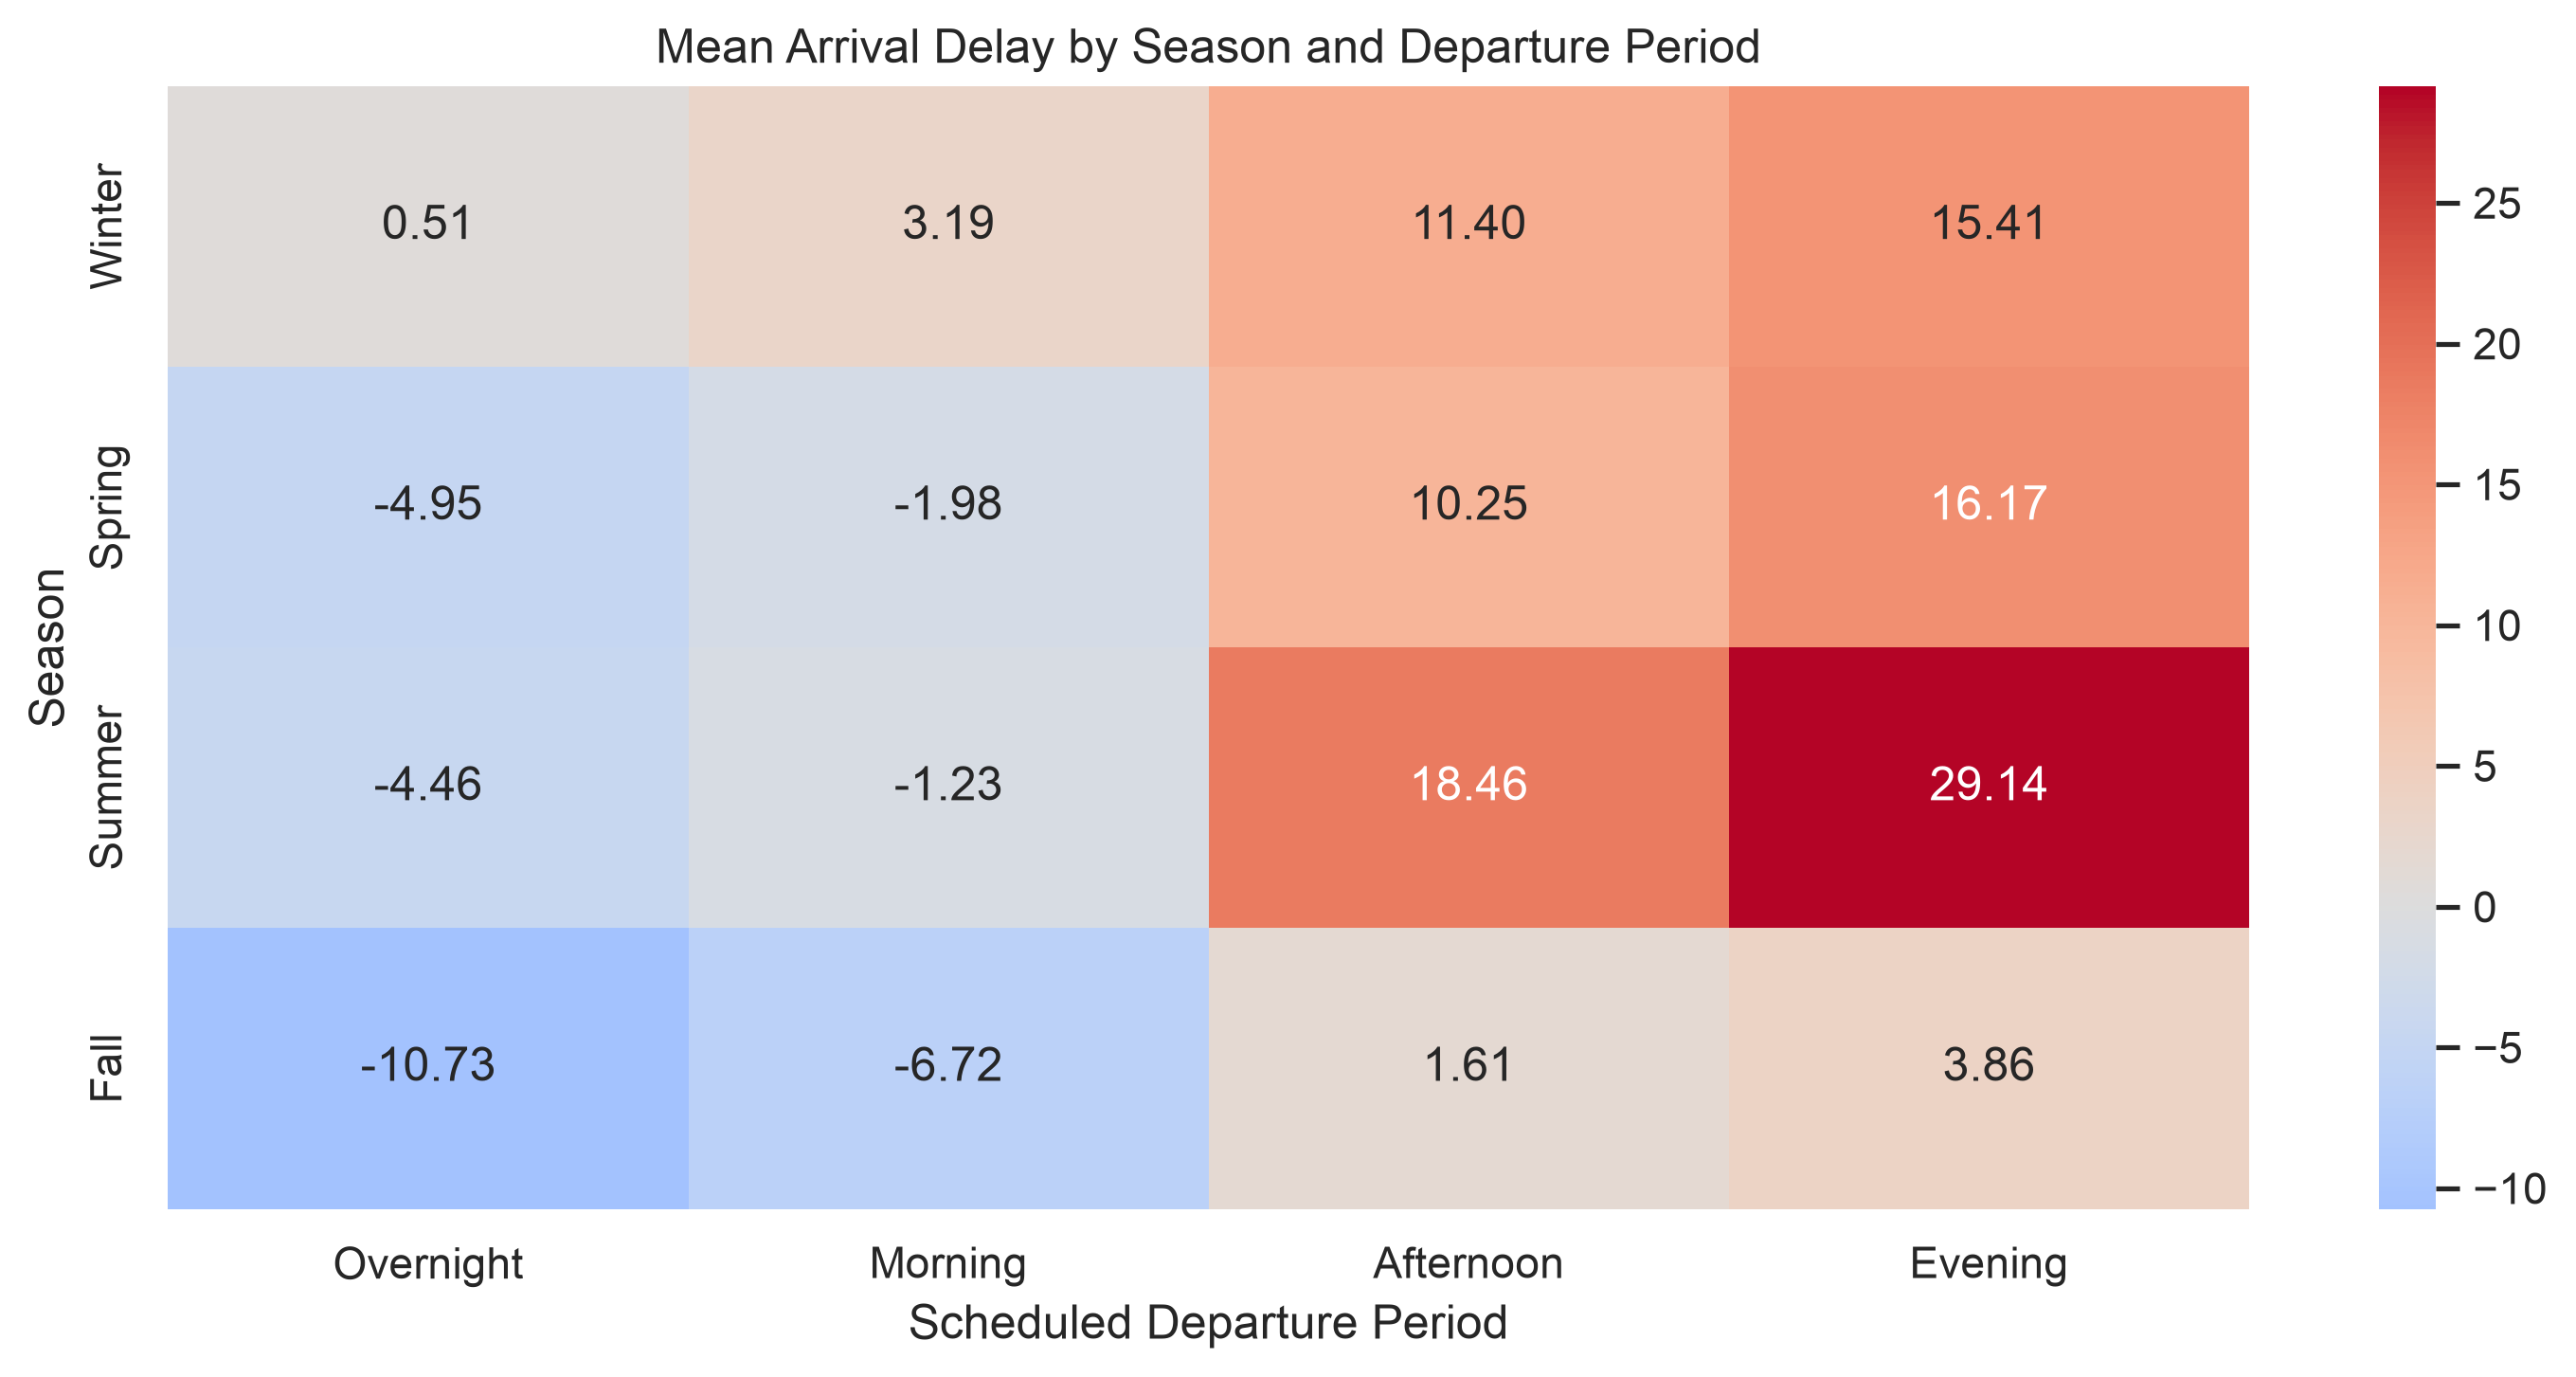

**Figure 2. Season and precipitation** — `integrated_season_precipitation.png`

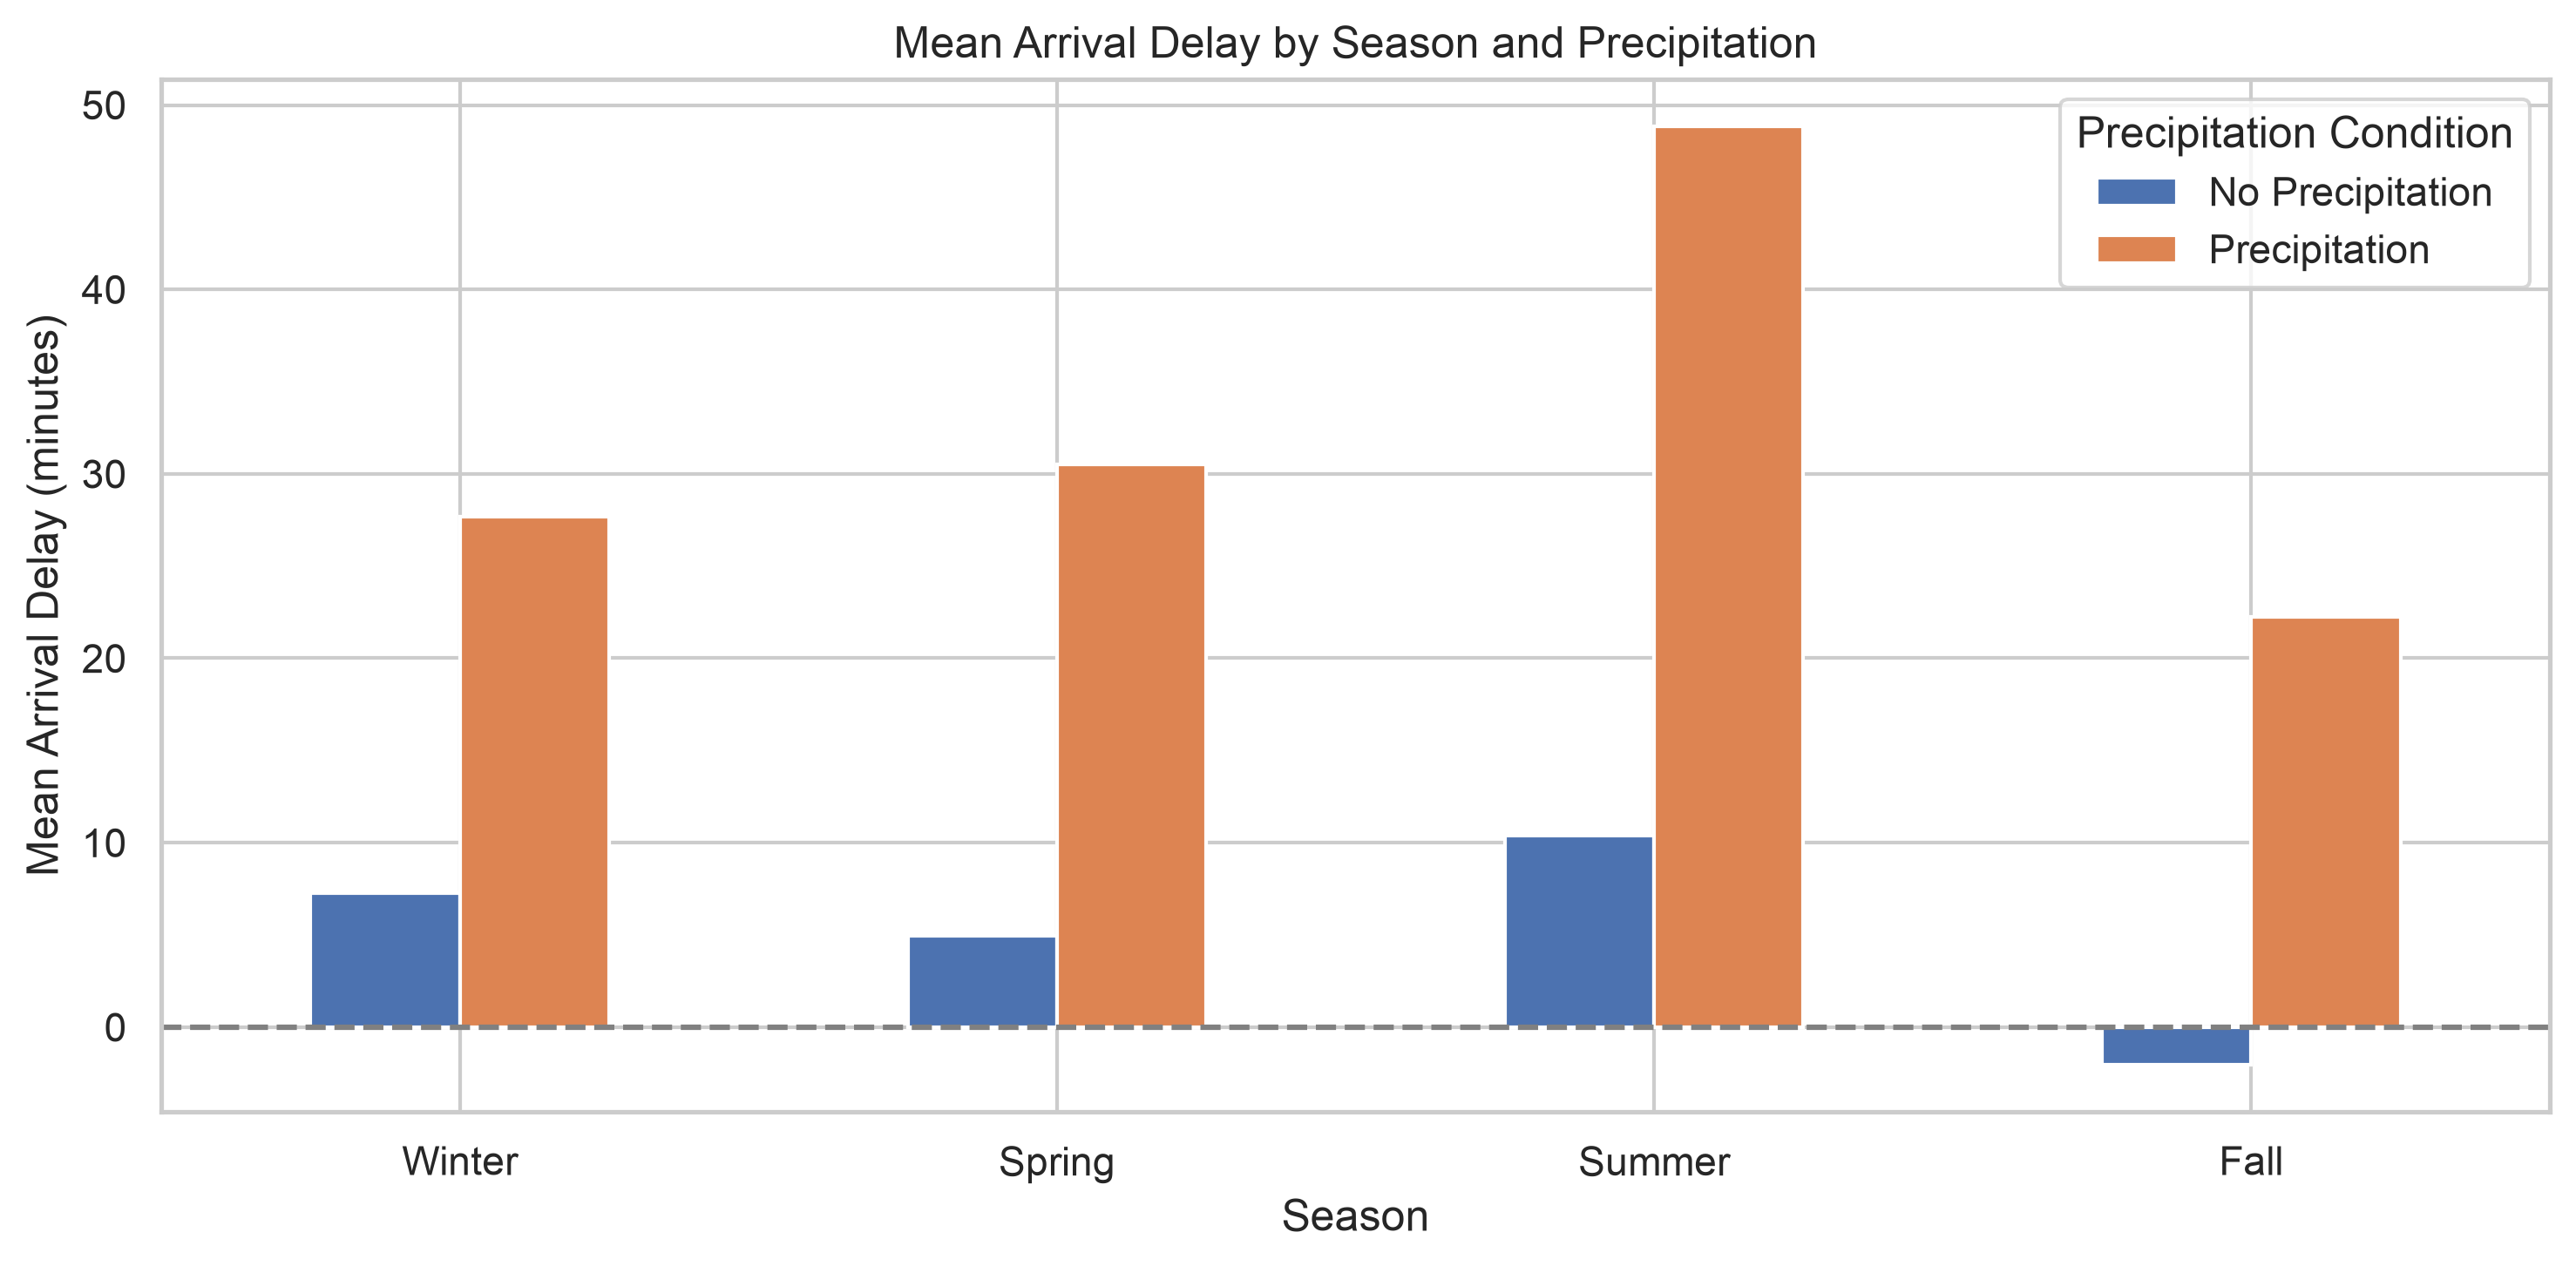

**Figure 3. Airport and scheduled departure period** — `integrated_airport_departure_heatmap.png`

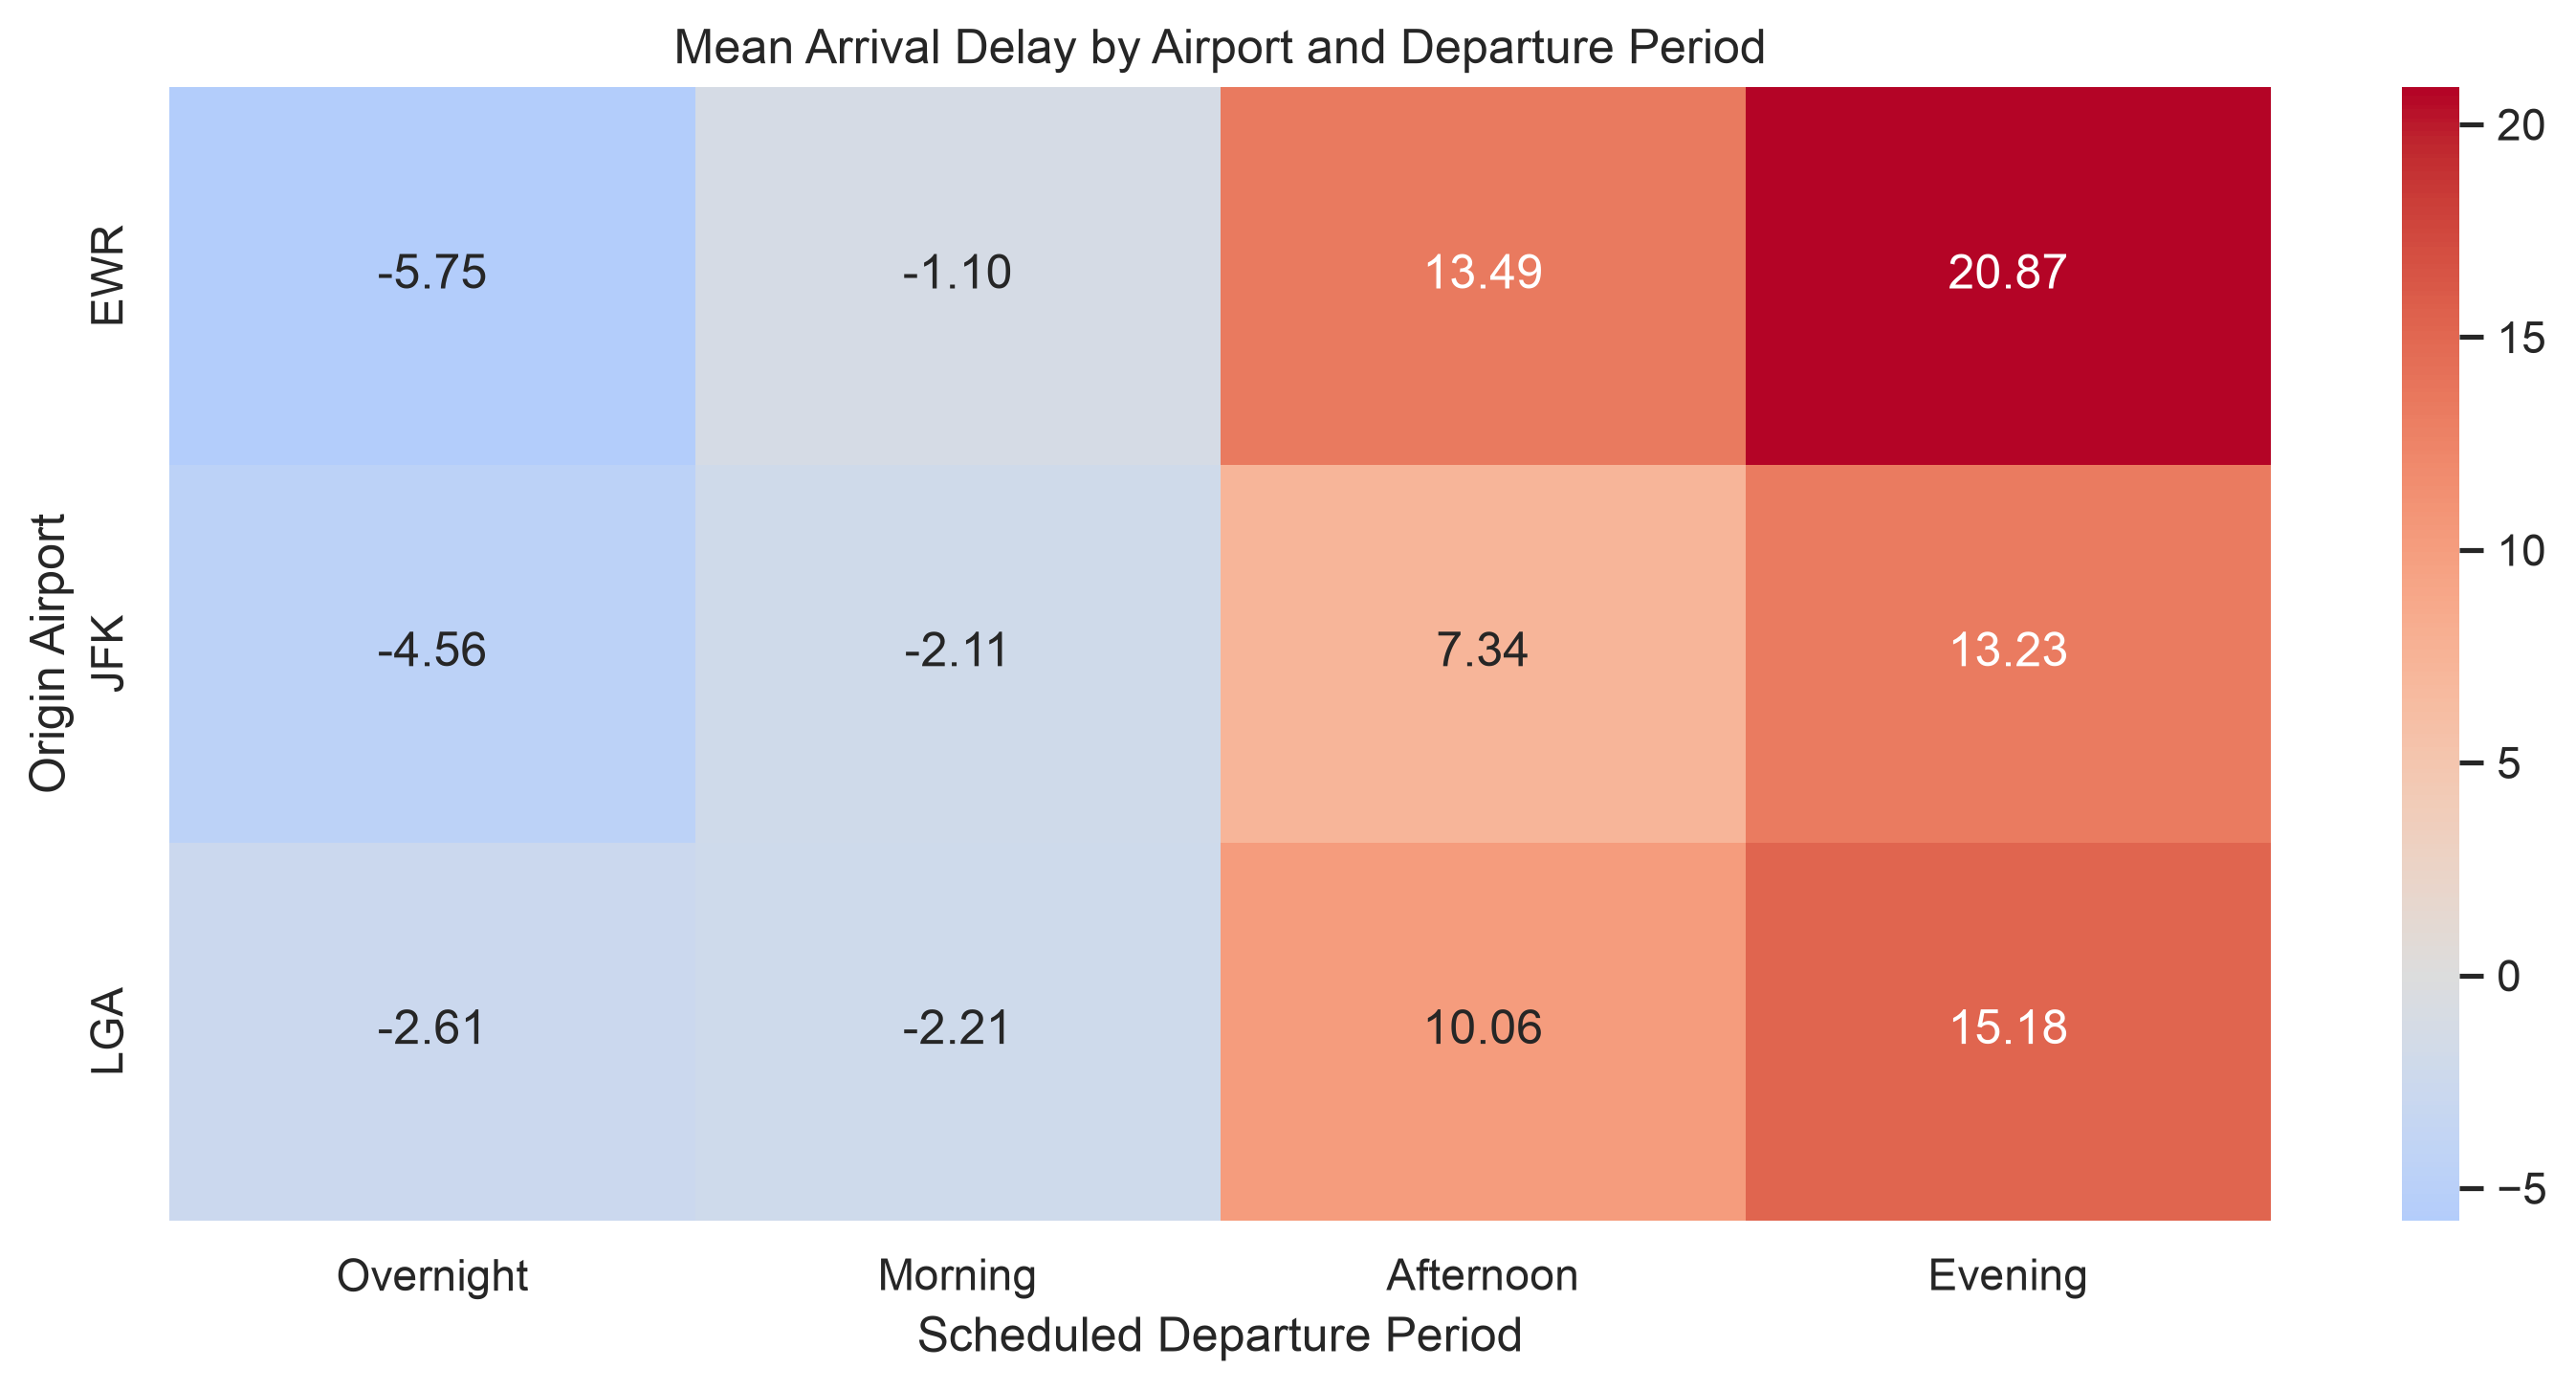

**Figure 4. Airline and airport** — `integrated_airline_airport_heatmap.png`

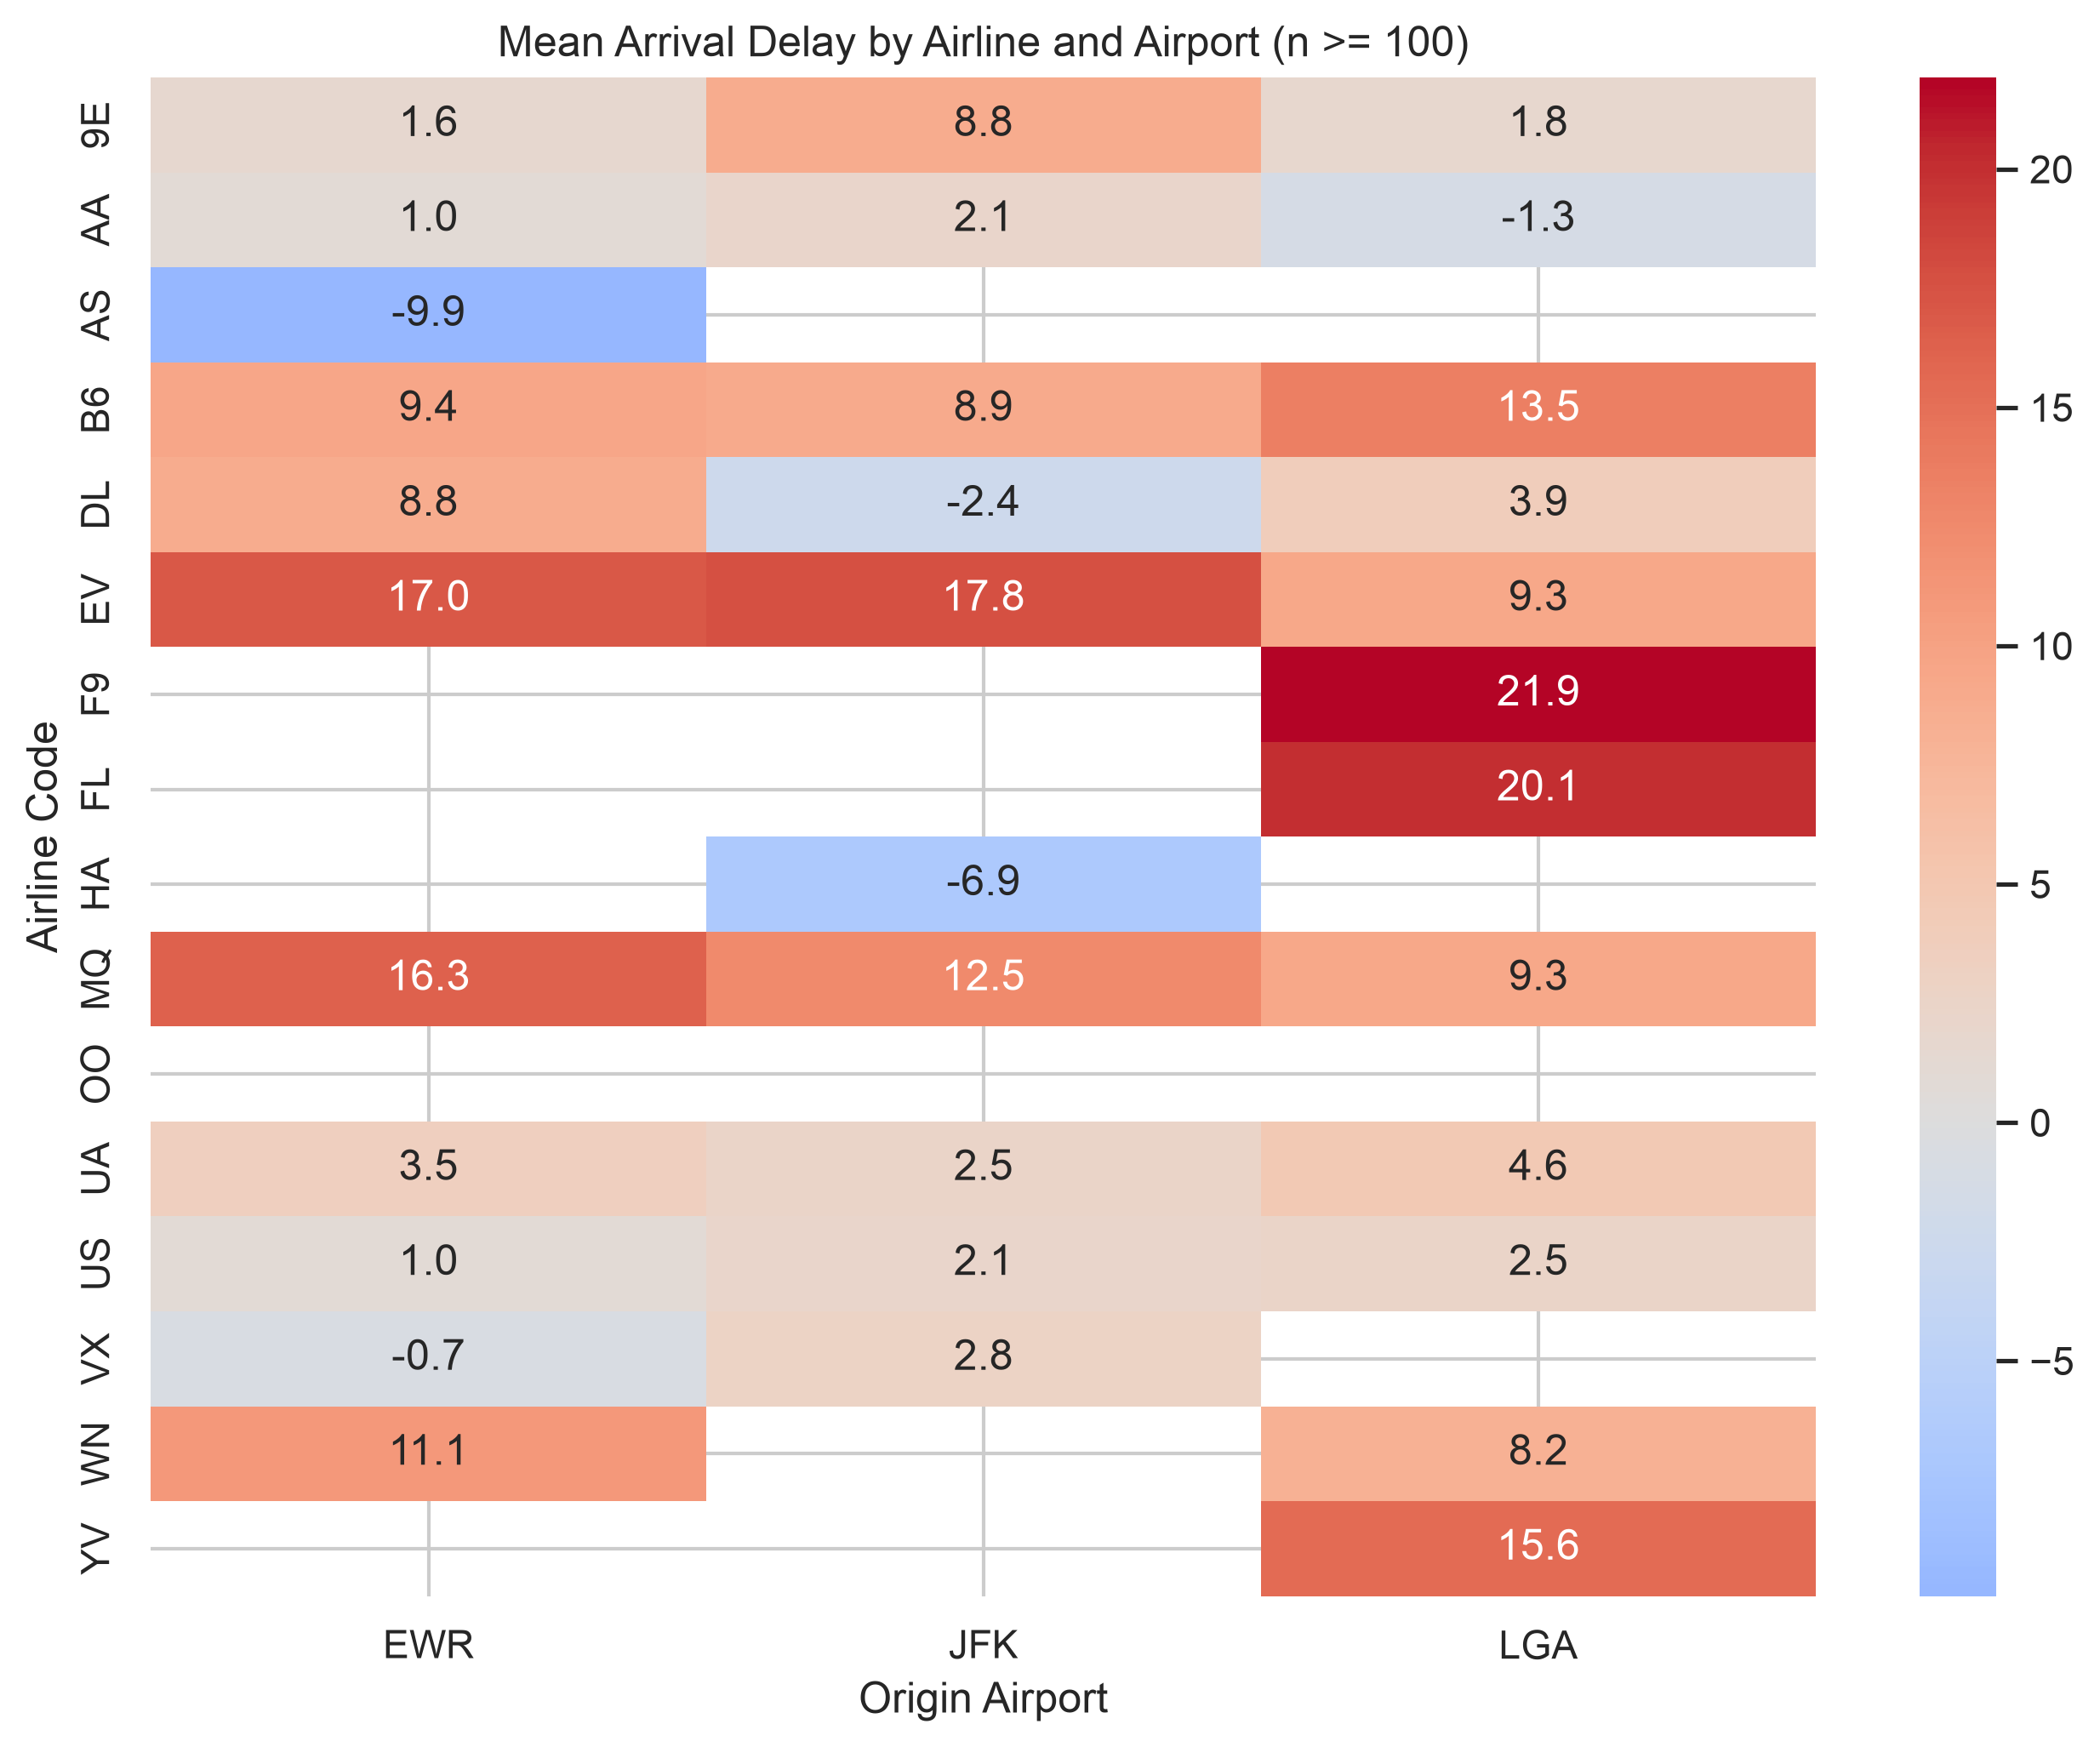

**Figure 5. Flight distance and departure period** — `integrated_distance_departure_heatmap.png`

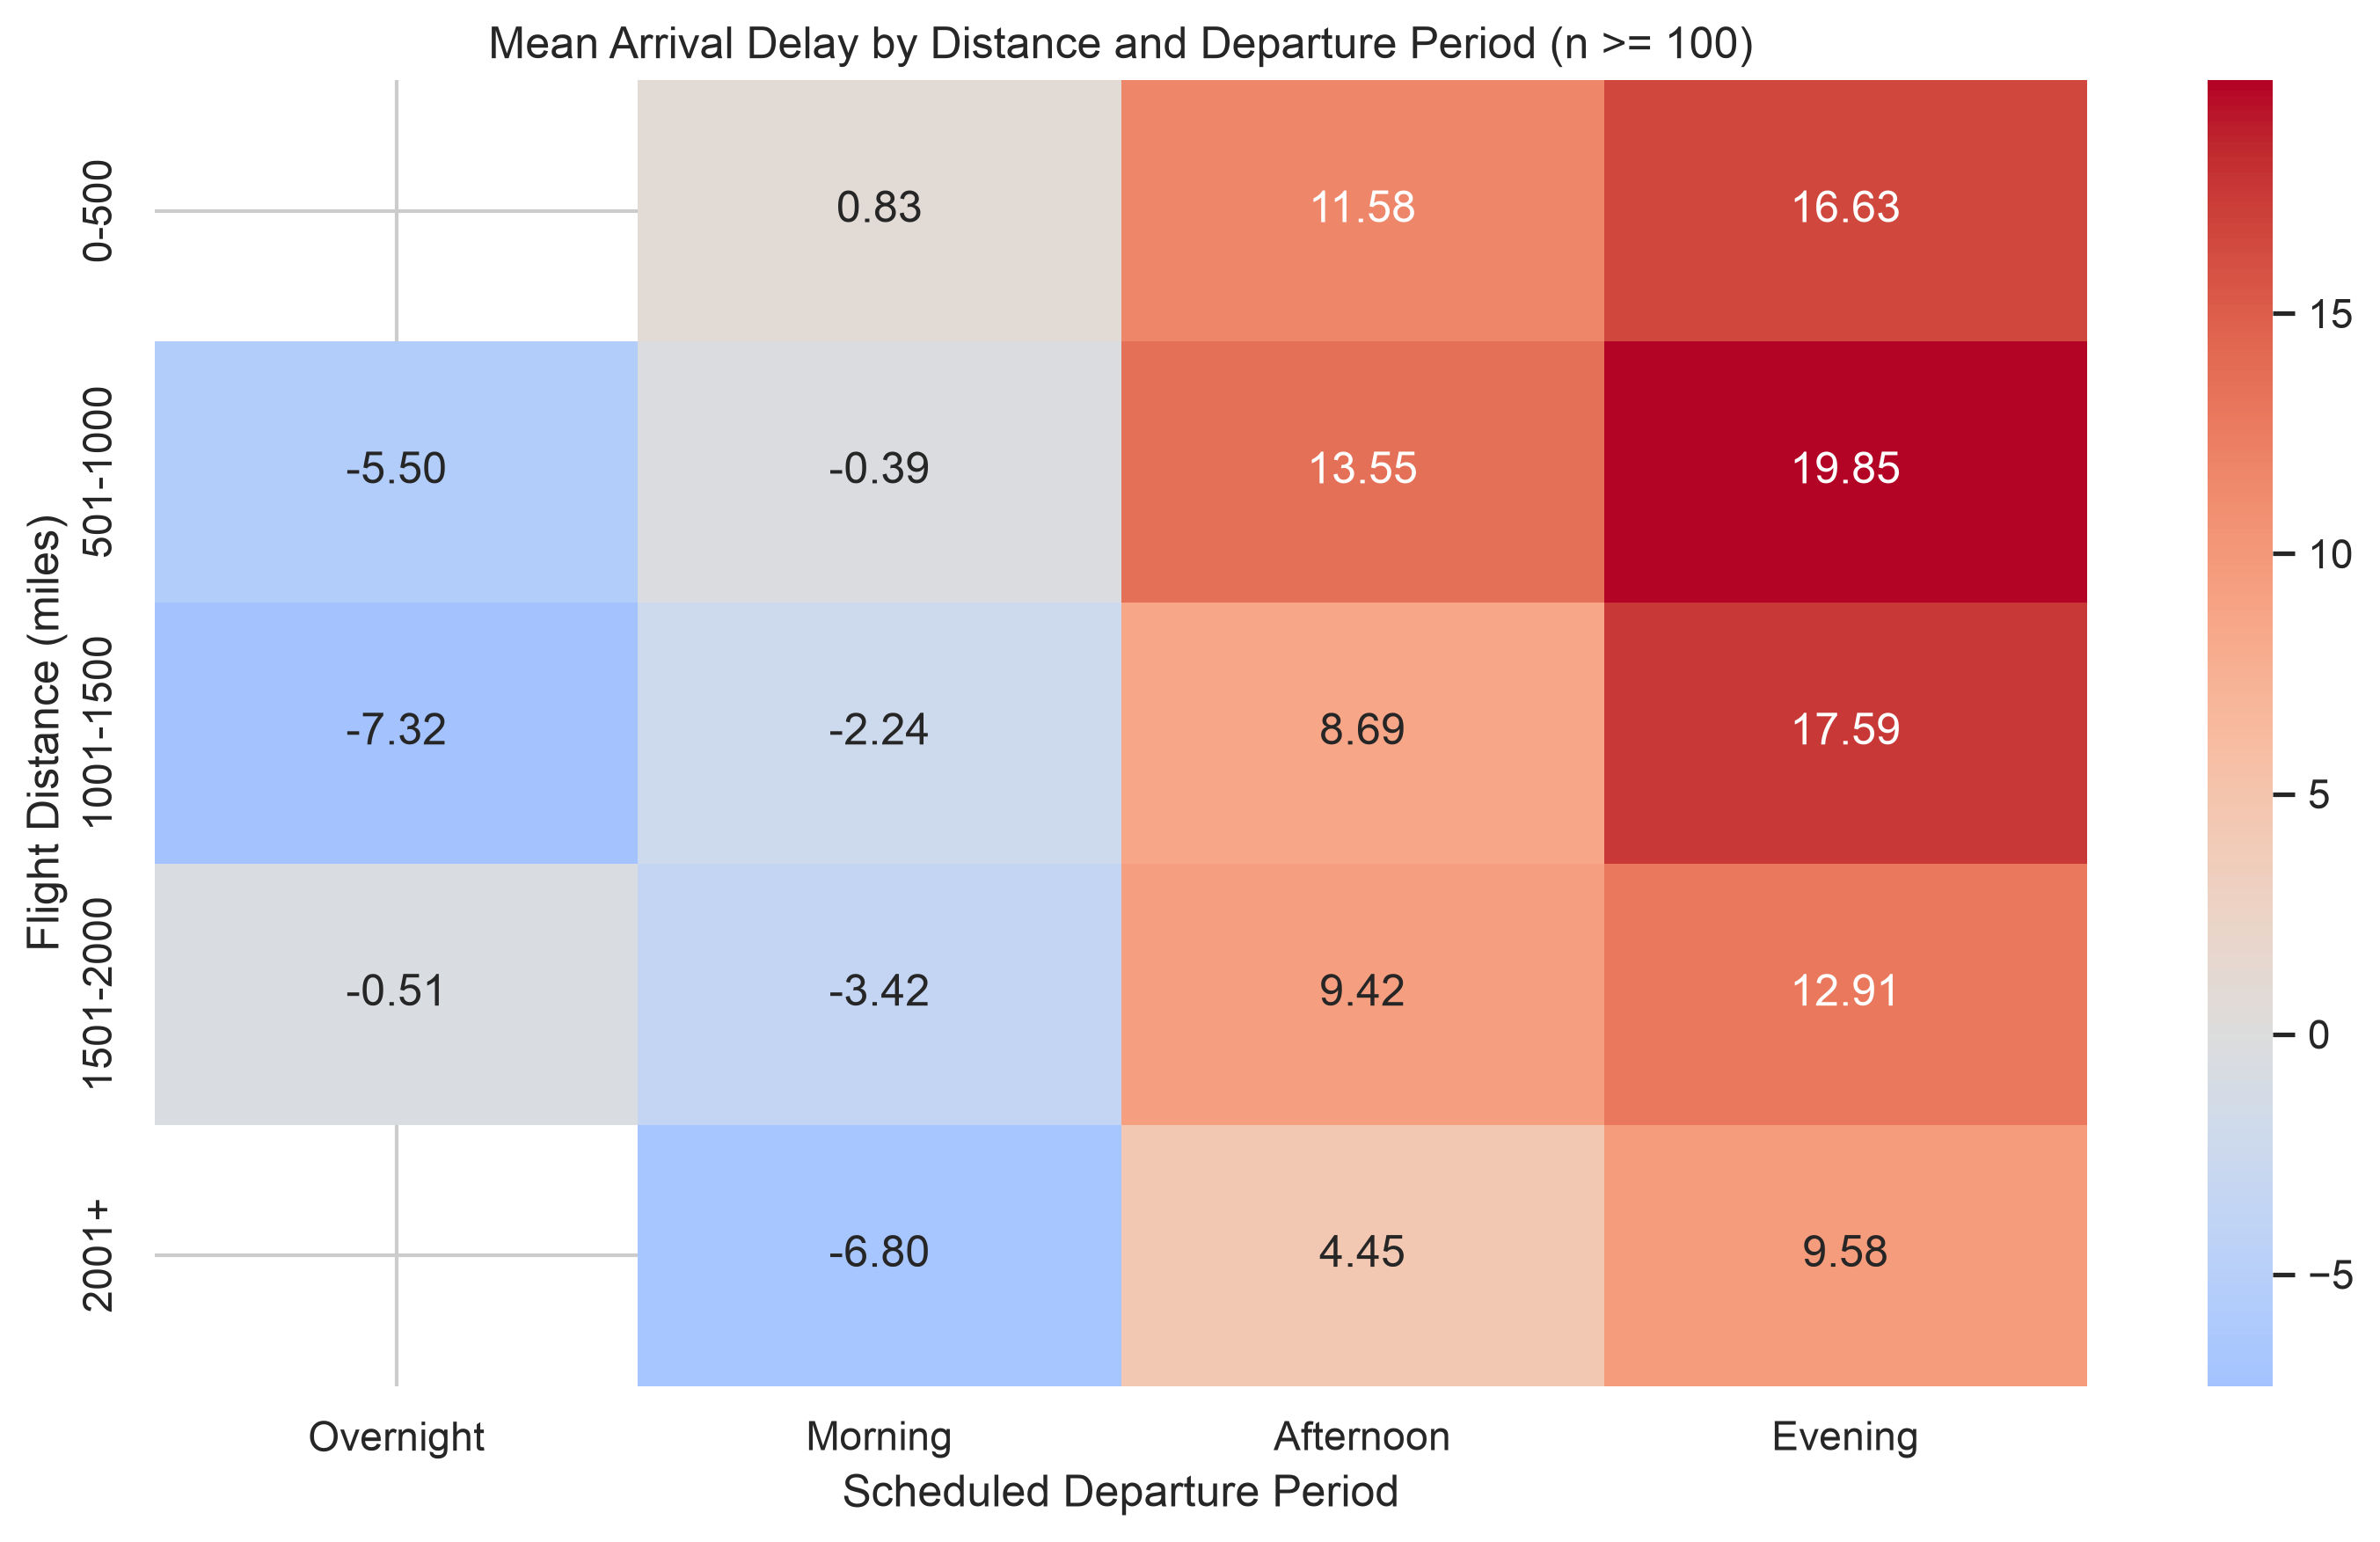

**Figure 6. Correlation matrix** — `integrated_correlation_matrix.png`

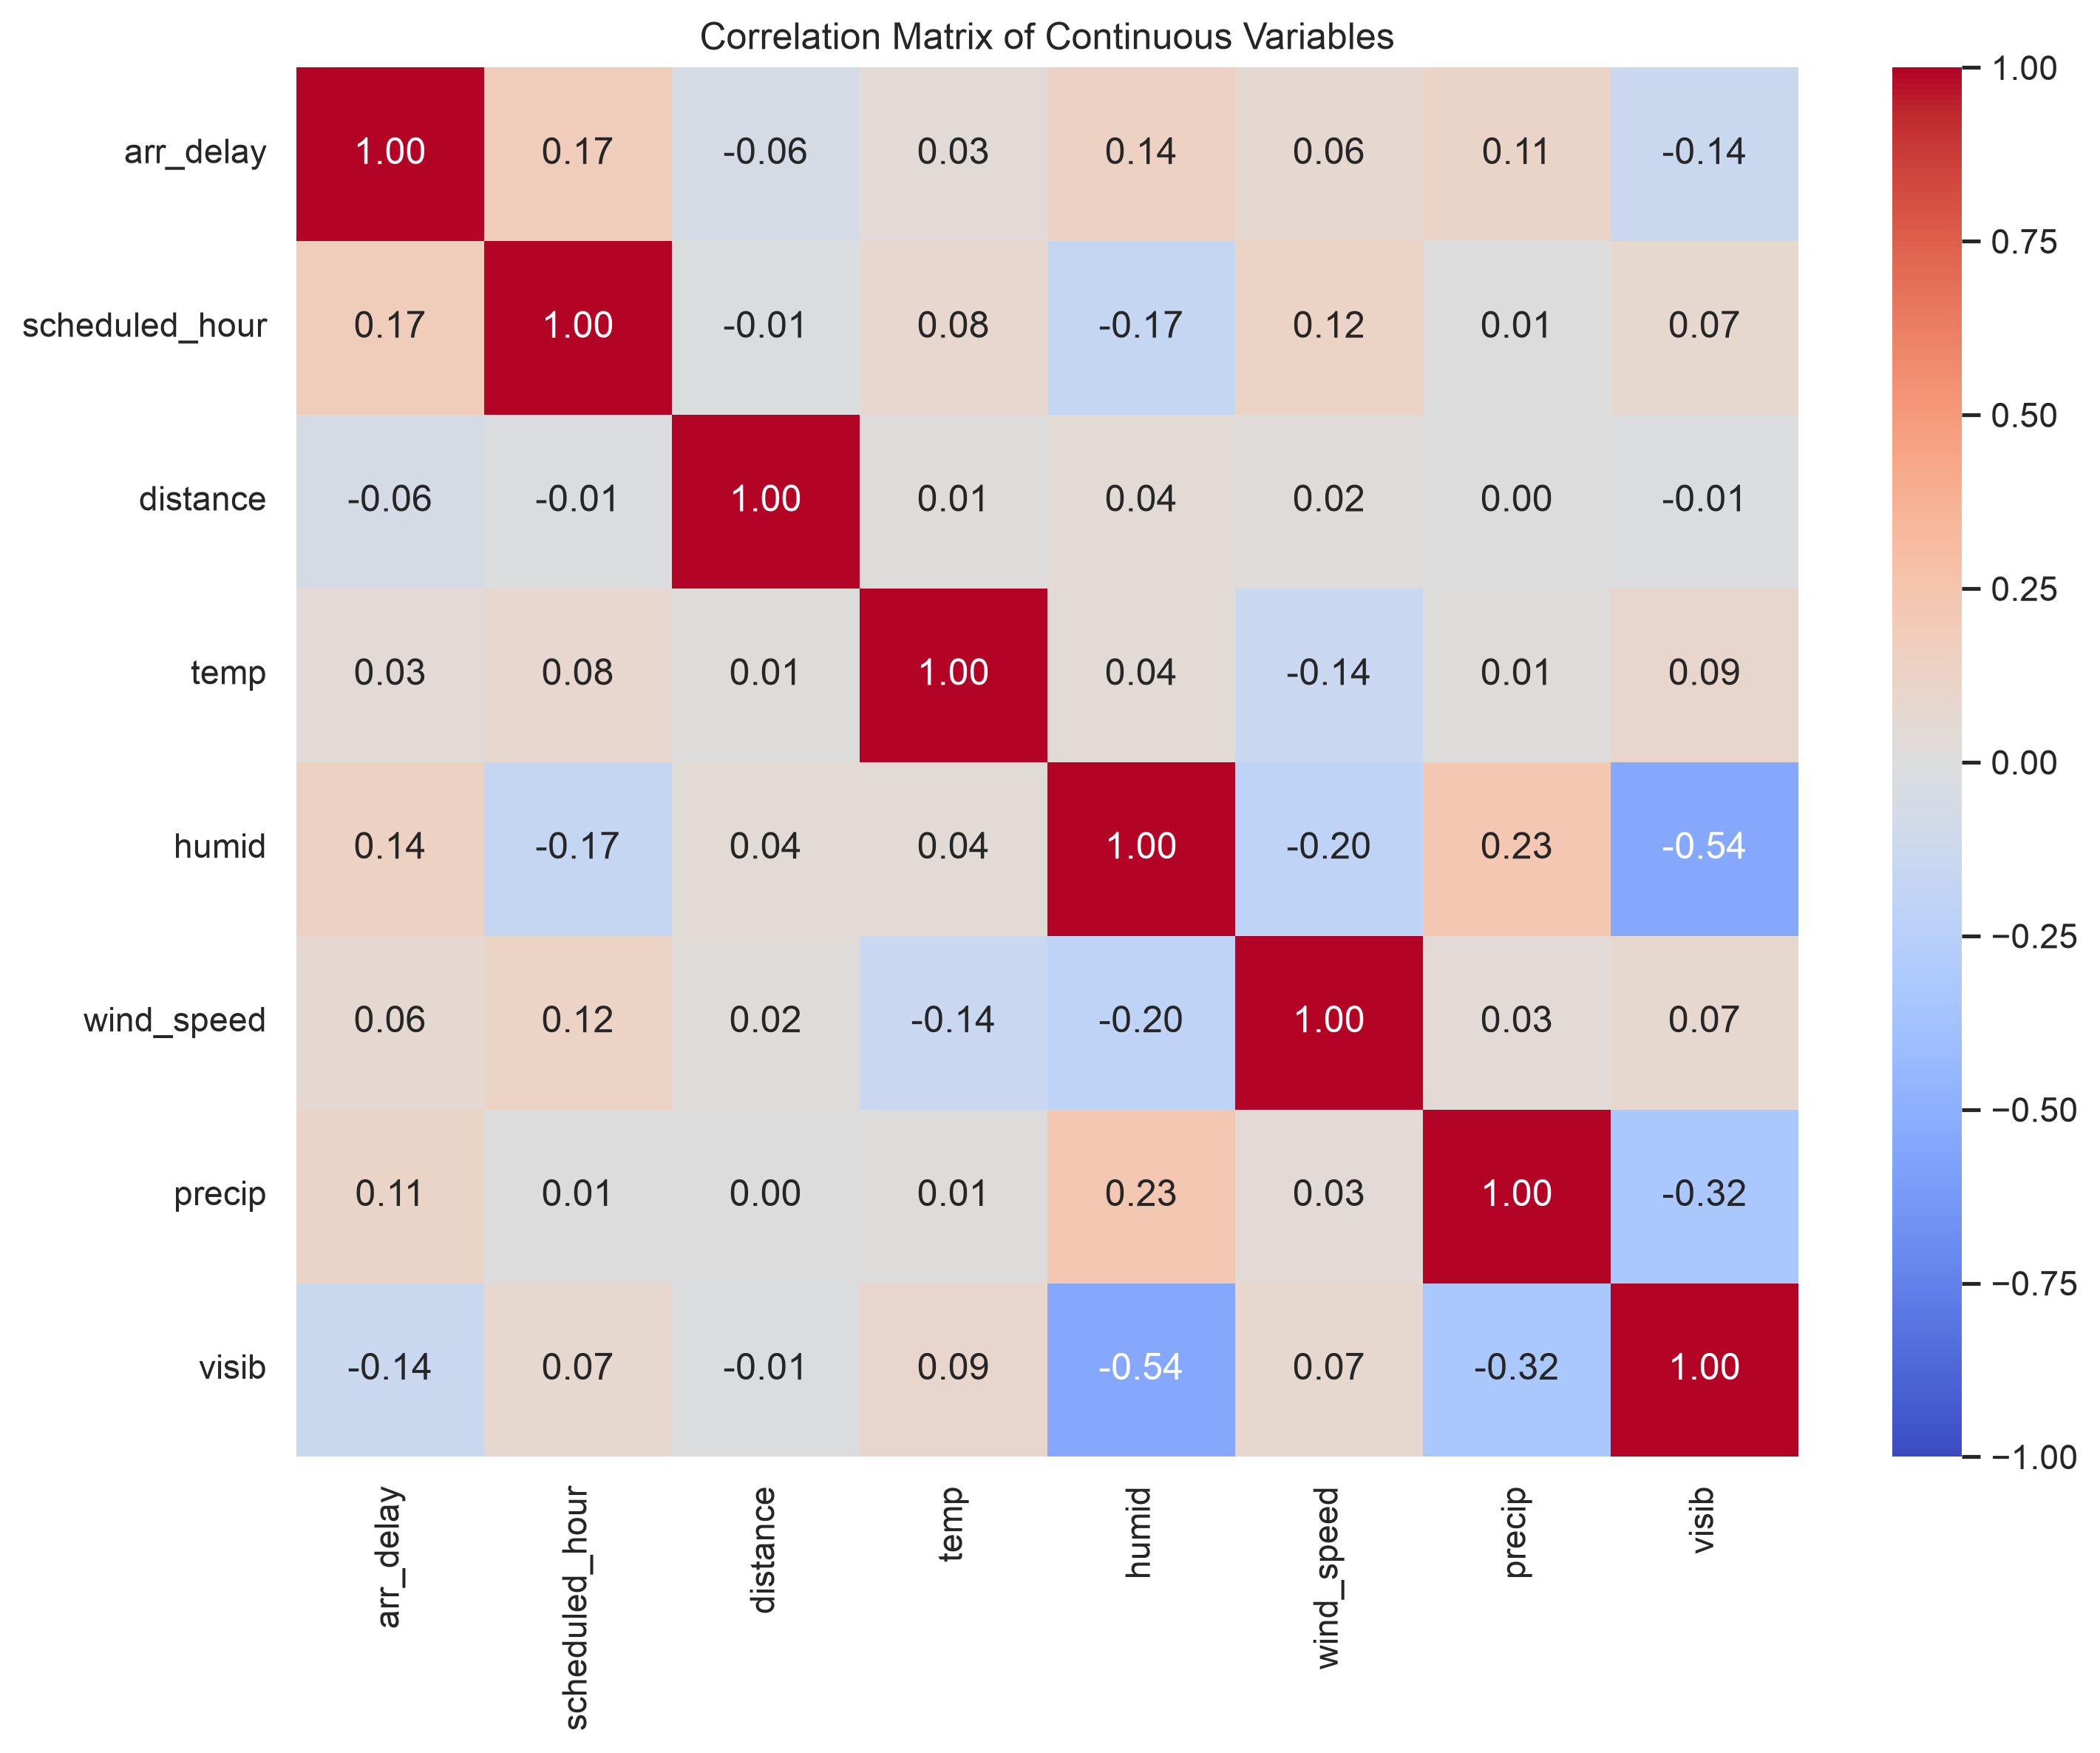

Figures displayed: 6/6


In [6]:
from IPython.display import Image, Markdown, display

selected_figures = [
    ("Figure 1. Season and scheduled departure period", "integrated_season_departure_heatmap.png"),
    ("Figure 2. Season and precipitation", "integrated_season_precipitation.png"),
    ("Figure 3. Airport and scheduled departure period", "integrated_airport_departure_heatmap.png"),
    ("Figure 4. Airline and airport", "integrated_airline_airport_heatmap.png"),
    ("Figure 5. Flight distance and departure period", "integrated_distance_departure_heatmap.png"),
    ("Figure 6. Correlation matrix", "integrated_correlation_matrix.png"),
]
missing_figures = []
for label, filename in selected_figures:
    path = FIGURES / filename
    if path.is_file():
        display(Markdown(f"**{label}** — `{filename}`"))
        display(Image(filename=str(path), width=850))
    else:
        missing_figures.append(filename)
        print(f"NOT FOUND: {path}")
print(f"Figures displayed: {len(selected_figures)-len(missing_figures)}/{len(selected_figures)}")
if missing_figures:
    print("Check the exact saved filenames in results/figures before submission.")


## 6. Data quality, uncertainty, and limitations
1. **Missing outcomes:** 9,430 original flights lack `arr_delay`; the analysis therefore describes flights with observed arrival delays rather than all departures. The missing outcome alone does not establish cancellation status.
2. **Weather coverage:** Hourly airport weather observations were left-joined on `origin` and `time_hour`; the original weather match rate was approximately **99.54%**, but some weather fields remain missing after merging. Different analyses may have slightly different sample sizes.
3. **Extreme values:** The Step 5 IQR check flagged **27,880 flights (8.52%)** as statistical outliers. They were retained rather than presumed erroneous. Sensitivity analyses showed that the mean is influenced by long delays.
4. **Observational data:** Airline, season, time, airport, and weather patterns may be confounded. Group differences and correlations should not be interpreted as independent effects or causes.
5. **Time and place:** The dataset covers departures from EWR, JFK, and LGA in **2013**. Findings cannot be assumed to generalize to other years, airports, or current schedules.
6. **Timing:** The flight `time_hour` used for weather matching is not identical to the derived scheduled departure hour. Hourly conditions are approximations of a flight's actual weather exposure.
7. **Unequal group sizes:** Some airlines, hours, and route categories contain few flights; those estimates are less stable.

## 7. Response to Milestone 2 feedback: data integration and use

**Flight–weather integration.** We started with the flight-level `flights` table and left-joined hourly airport weather observations using the composite key `origin` + `time_hour`. We verified uniqueness of the weather-side key and used `validate="many_to_one"` so that the join could not silently multiply flight records. Of 336,776 original flights, 335,220 (99.54%) matched a weather record; 1,556 did not. After excluding 9,430 records with missing `arr_delay`, 327,346 flight records remained.

**Meaning and limitations of the timestamps.** `scheduled_hour` is derived from `sched_dep_time` and represents the scheduled departure hour for flight-time comparisons. In contrast, the `time_hour` column used for weather matching is the hourly timestamp provided in the original flight data; it is **not** constructed from `scheduled_hour`. Consequently, the merged weather is an hourly airport-level approximation and should not be described as exact weather at scheduled departure.

**How weather is used.** We summarize arrival delays by observed precipitation and weather ranges, then compare weather patterns jointly with season in the integrated EDA. For Milestone 4, weather variables will enter a multivariable regression alongside season, airline, scheduled departure hour, and distance. Flights with missing individual weather fields are retained in the descriptive dataset, but complete-case counts must be reported for any model requiring those fields.

**Outcome inclusion.** Missing `arr_delay` values cannot support an arrival-delay analysis. These flights were excluded from the analytical sample; missing `arr_delay` alone does not prove cancellation or diversion.

## 8. Response to Milestone 2 feedback: analysis plan linked to the research question

The table identifies **planned inferential analyses**, not analyses already performed.

| Research question component | Descriptive evidence completed | Planned statistical analysis (Milestone 4) |
|---|---|---|
| Season | Seasonal mean/median delays, delay rates, season × departure period | One-way ANOVA for unadjusted seasonal mean differences, with assumptions assessed; season indicators in multivariable regression |
| Airline | Carrier-level mean/median delays and sample sizes; airline × airport | Airline categorical indicators in multivariable regression, with careful interpretation of small groups |
| Scheduled departure time | Hourly/period summaries and interactions with season/airport | `scheduled_hour` as a predictor in multivariable regression; assess whether a linear hour effect is adequate |
| Distance | Distance bins, scatter/LOWESS and Pearson correlation | `distance` as a predictor; assess nonlinearity |
| Weather | Precipitation, wind, visibility, temperature and humidity summaries | Selected weather predictors in multivariable regression; check missingness and collinearity |
| Airport context | EWR/JFK/LGA summaries and cross-tabulations | Consider `origin` as an adjustment variable |

**Proposed outcome:** `arr_delay` in minutes. **Proposed primary model:** multiple linear regression with season, airline, scheduled departure hour, flight distance, and selected weather variables; consider airport as a covariate. Compare a flight-only specification against a flight-plus-weather specification on the **same complete-case sample** (previously assessed at 325,724 records for the selected weather fields).

**Model assessment planned:** residual plots, heteroskedasticity, influential observations, multicollinearity, and out-of-sample or otherwise appropriate validation. Because delays are strongly right-skewed, we will assess sensitivity to extreme delays and use an appropriate uncertainty method if assumptions are problematic. Statistical significance, effect sizes, confidence intervals, and model performance **will only be reported after fitting the models**.

**Interpretation:** EDA comparisons are unadjusted associations; neither the EDA nor the proposed observational regression establishes causality.

## 9. Preliminary implications and next analysis
**Preliminary operational implications:** Airline managers may wish to examine summer evening operations, precipitation-related disruptions, and differences across departure airports more closely. These are **areas for further investigation**, not validated causal recommendations.

**Next milestone — statistical analysis (not performed here):**
1. Fit an interpretable multivariable model for `arr_delay` with season, carrier, scheduled departure hour, distance, weather, and potentially origin airport.
2. Compare flight-only and flight-plus-weather models using the **same complete-case sample** where appropriate.
3. Evaluate residual distribution, heteroskedasticity, influential delays, multicollinearity, and model performance/validation.
4. Report estimates, uncertainty, statistical significance (if tested), assumptions, and practical relevance. Avoid causal language.

**References**
- `nycflights13` dataset documentation: https://nycflights13.tidyverse.org/
- Project Milestone 2 proposal (team-submitted source document)
- Team notebooks Steps 1–6, including the data-quality audit and eight EDA analyses